# Feature Engineering Review

## Orchestra Subscription Prediction

This notebook examines the account-level datasets generated by `src/features.py`.

### Objectives
1. Build and inspect the master training and test datasets
2. Verify dataset integrity and feature consistency
3. Examine engineered feature distributions and missingness
4. Explore relationships between features and subscription purchases
5. Compare training and test feature distributions

The feature engineering pipeline is reusable and does not use target labels to construct predictive features.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)

# Locate the repository root
ROOT = Path.cwd()

if not (ROOT / "src" / "features.py").exists():
    ROOT = ROOT.parent

assert (ROOT / "src" / "features.py").exists(), "Repository root not found."

sys.path.insert(0, str(ROOT))

from src.features import load_data, build_master_datasets

raw_data = load_data(ROOT / "data" / "raw")

train_master, test_master = build_master_datasets(raw_data)

print("Train:", train_master.shape)
print("Test: ", test_master.shape)

Train: (6941, 41)
Test:  (2975, 40)


## 1. Master Dataset Inspection

Examine the generated account-level datasets.

Each account should appear exactly once. The training and test datasets should share identical predictive features, with the target label present only in training.

In [2]:
print("Training dataset:")
display(train_master.head(5).T)

print("\nTest dataset:")
display(test_master.head(5).T)

print("\nIntegrity checks:")

assert len(train_master) == len(raw_data["train"])
assert len(test_master) == len(raw_data["test"])

assert train_master["account.id"].is_unique
assert test_master["account.id"].is_unique

assert (
    train_master.columns.drop("label").tolist()
    == test_master.columns.tolist()
)

assert train_master["label"].notna().all()

print("All integrity checks passed.")

Training dataset:


,0,1,2,3,4
account.id,001i000000NuRo3,001i000000NuRxd,001i000000NuQGN,001i000000NuPfL,001i000000NuQkP
label,0,0,0,0,0
billing_city,NaN,NaN,Walnut Creek,Brisbane,Oakland
billing_zip,<NA>,<NA>,94597,94005,94610
donation_2013,0.0,0.0,0.0,0.0,0.0
donated_2013,0,0,0,0,0
zip_state,NaN,NaN,CA,CA,CA
zip_lat,NaN,NaN,37.91,37.68,37.81
zip_long,NaN,NaN,-122.07,-122.41,-122.24
sub_records,0.0,0.0,0.0,1.0,0.0



Test dataset:


,0,1,2,3,4
account.id,001i000000NuQ6Y,001i000000NuQXz,001i000000NuRDC,001i000000NuQeg,001i000000NuOQc
billing_city,San Francisco,Oakland,Oakland,San Anselmo,San Carlos
billing_zip,94115,94606,94609,94960,94070
donation_2013,0.0,0.0,0.0,0.0,0.0
donated_2013,0,0,0,0,0
zip_state,CA,CA,CA,CA,CA
zip_lat,37.78,37.78,37.83,37.99,37.49
zip_long,-122.43,-122.24,-122.26,-122.58,-122.26
sub_records,6.0,1.0,0.0,0.0,6.0
sub_unique_seasons,6.0,1.0,0.0,0.0,6.0



Integrity checks:
All integrity checks passed.


## 2. Engineered Feature Summary

Examine every feature's data type, completeness, and number of distinct values.

Missing values in engineered features may indicate that an account has no relevant historical activity. These should be distinguished from incomplete source data.

In [3]:
feature_catalog = pd.DataFrame({
    "Data Type": train_master.dtypes.astype(str),
    "Missing (%)": train_master.isna().mean() * 100,
    "Unique Values": train_master.nunique(dropna=True),
})

display(
    feature_catalog
    .sort_values("Missing (%)", ascending=False)
    .round(2)
)

,Data Type,Missing (%),Unique Values
ticket_last_year,float64,89.53,4
ticket_recency_seasons,float64,89.53,4
ticket_mean_seats,float64,89.53,24
sub_last_price_level,float64,71.04,5
sub_last_package,object,68.26,10
sub_last_location,object,68.26,8
sub_mean_seats,float64,68.23,107
sub_last_year,float64,68.23,21
sub_recency_seasons,float64,68.23,21
sub_consistency,float64,68.23,87


In [4]:
numeric_features = (
    train_master
    .drop(columns=["label"])
    .select_dtypes(include="number")
)

summary = numeric_features.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
).T

display(summary.round(2))

,count,mean,std,min,25%,50%,75%,90%,max
donation_2013,6941.0,58.62,1133.86,0.00,0.00,0.00,0.00,0.00,60000.00
donated_2013,6941.0,0.04,0.19,0.00,0.00,0.00,0.00,0.00,1.00
zip_lat,5869.0,37.69,1.87,20.07,37.56,37.79,37.90,38.03,61.21
zip_long,5869.0,-120.49,7.83,-159.52,-122.42,-122.24,-122.07,-119.73,-73.05
sub_records,6941.0,1.43,3.70,0.00,0.00,0.00,1.00,4.00,21.00
sub_unique_seasons,6941.0,1.43,3.70,0.00,0.00,0.00,1.00,4.00,21.00
sub_total_seats,6941.0,2.51,6.78,0.00,0.00,0.00,2.00,7.00,70.00
sub_mean_seats,2205.0,1.72,0.54,1.00,1.00,2.00,2.00,2.00,5.00
sub_mean_tier,2205.0,1.41,0.62,0.50,1.00,1.30,2.00,2.00,5.00
sub_first_year,2205.0,1998.20,5.64,1993.00,1993.00,1996.00,2001.00,2007.00,2013.00


## 3. Features vs. Subscription Purchases

Compare important engineered features between subscribers and non-subscribers.

These descriptive comparisons help identify promising predictors, although their independent contributions must eventually be evaluated using cross-validation.

In [5]:
important_features = [
    "sub_recency_seasons",
    "sub_unique_seasons",
    "sub_streak_to_2013",
    "sub_seasons_last_3",
    "sub_consistency",
    "ticket_records",
    "ticket_total_seats",
    "donation_2013",
]

comparison = (
    train_master
    .groupby("label")[important_features]
    .median()
    .T
)

comparison.columns = [
    "Non-Subscribers (Median)",
    "Subscribers (Median)"
]

display(comparison.round(2))

,Non-Subscribers (Median),Subscribers (Median)
sub_recency_seasons,15.0,1.0
sub_unique_seasons,0.0,11.5
sub_streak_to_2013,0.0,8.0
sub_seasons_last_3,0.0,3.0
sub_consistency,1.0,1.0
ticket_records,0.0,0.0
ticket_total_seats,0.0,0.0
donation_2013,0.0,27.5


,Accounts,Purchase Rate
recency_group,,
1,345,81.74
2,83,13.25
3,52,7.69
4–5,105,2.86
6–10,223,0.00
11+,1397,0.00
Never,4736,0.68


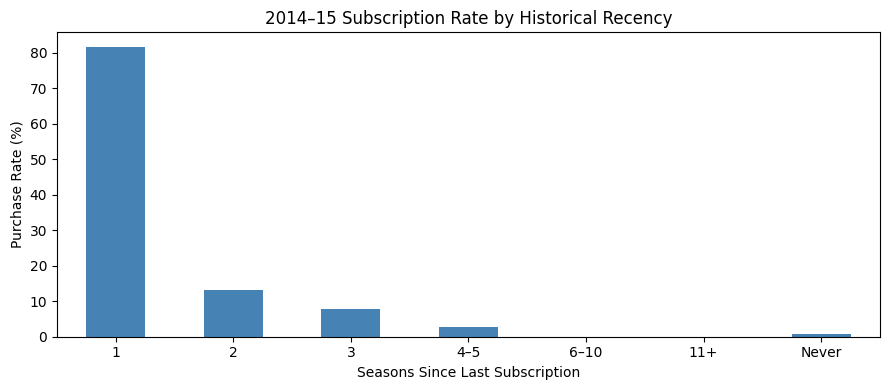

In [6]:
recency = pd.cut(
    train_master["sub_recency_seasons"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4–5", "6–10", "11+"]
)

recency = recency.cat.add_categories("Never").fillna("Never")

recency_analysis = (
    train_master
    .assign(recency_group=recency)
    .groupby("recency_group", observed=True)["label"]
    .agg(["size", "mean"])
)

recency_analysis.columns = ["Accounts", "Purchase Rate"]
recency_analysis["Purchase Rate"] *= 100

display(recency_analysis.round(2))

ax = recency_analysis["Purchase Rate"].plot(
    kind="bar",
    figsize=(9, 4),
    color="steelblue",
)

ax.set_title("2014–15 Subscription Rate by Historical Recency")
ax.set_xlabel("Seasons Since Last Subscription")
ax.set_ylabel("Purchase Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Train vs. Test Feature Distributions

Compare important features between the training and test populations.

Large distribution differences could indicate that validation performance may not generalize as expected to the Kaggle test set.

In [7]:
comparison_features = [
    "has_subscription_history",
    "sub_active_2013",
    "sub_unique_seasons",
    "sub_recency_seasons",
    "has_ticket_history",
    "ticket_records",
    "donated_2013",
    "donation_2013",
]

rows = []

for feature in comparison_features:
    rows.append({
        "Feature": feature,
        "Train Mean": train_master[feature].mean(),
        "Test Mean": test_master[feature].mean(),
        "Train Missing (%)": train_master[feature].isna().mean() * 100,
        "Test Missing (%)": test_master[feature].isna().mean() * 100,
    })

display(pd.DataFrame(rows).round(2))

,Feature,Train Mean,Test Mean,Train Missing (%),Test Missing (%)
0,has_subscription_history,0.32,0.32,0.00,0.0
1,sub_active_2013,0.05,0.05,0.00,0.0
2,sub_unique_seasons,1.43,1.46,0.00,0.0
3,sub_recency_seasons,11.70,11.71,68.23,68.3
4,has_ticket_history,0.10,0.10,0.00,0.0
5,ticket_records,0.14,0.12,0.00,0.0
6,donated_2013,0.04,0.04,0.00,0.0
7,donation_2013,58.62,163.66,0.00,0.0


## 5. Feature Engineering Conclusions

### Dataset Integrity
_To be completed after reviewing the results._

### Important Predictive Features
_To be completed after reviewing the results._

### Missingness and Feature Quality
_To be completed after reviewing the results._

### Train/Test Consistency
_To be completed after reviewing the results._

### Next Steps
- Implement baseline models
- Establish stratified cross-validation
- Measure out-of-fold AUROC
- Evaluate feature importance
- Test additional feature groups